<a href="https://colab.research.google.com/github/moysessevan/termodinamica-python/blob/main/cod_2_3_diagrama_Tv_agua.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

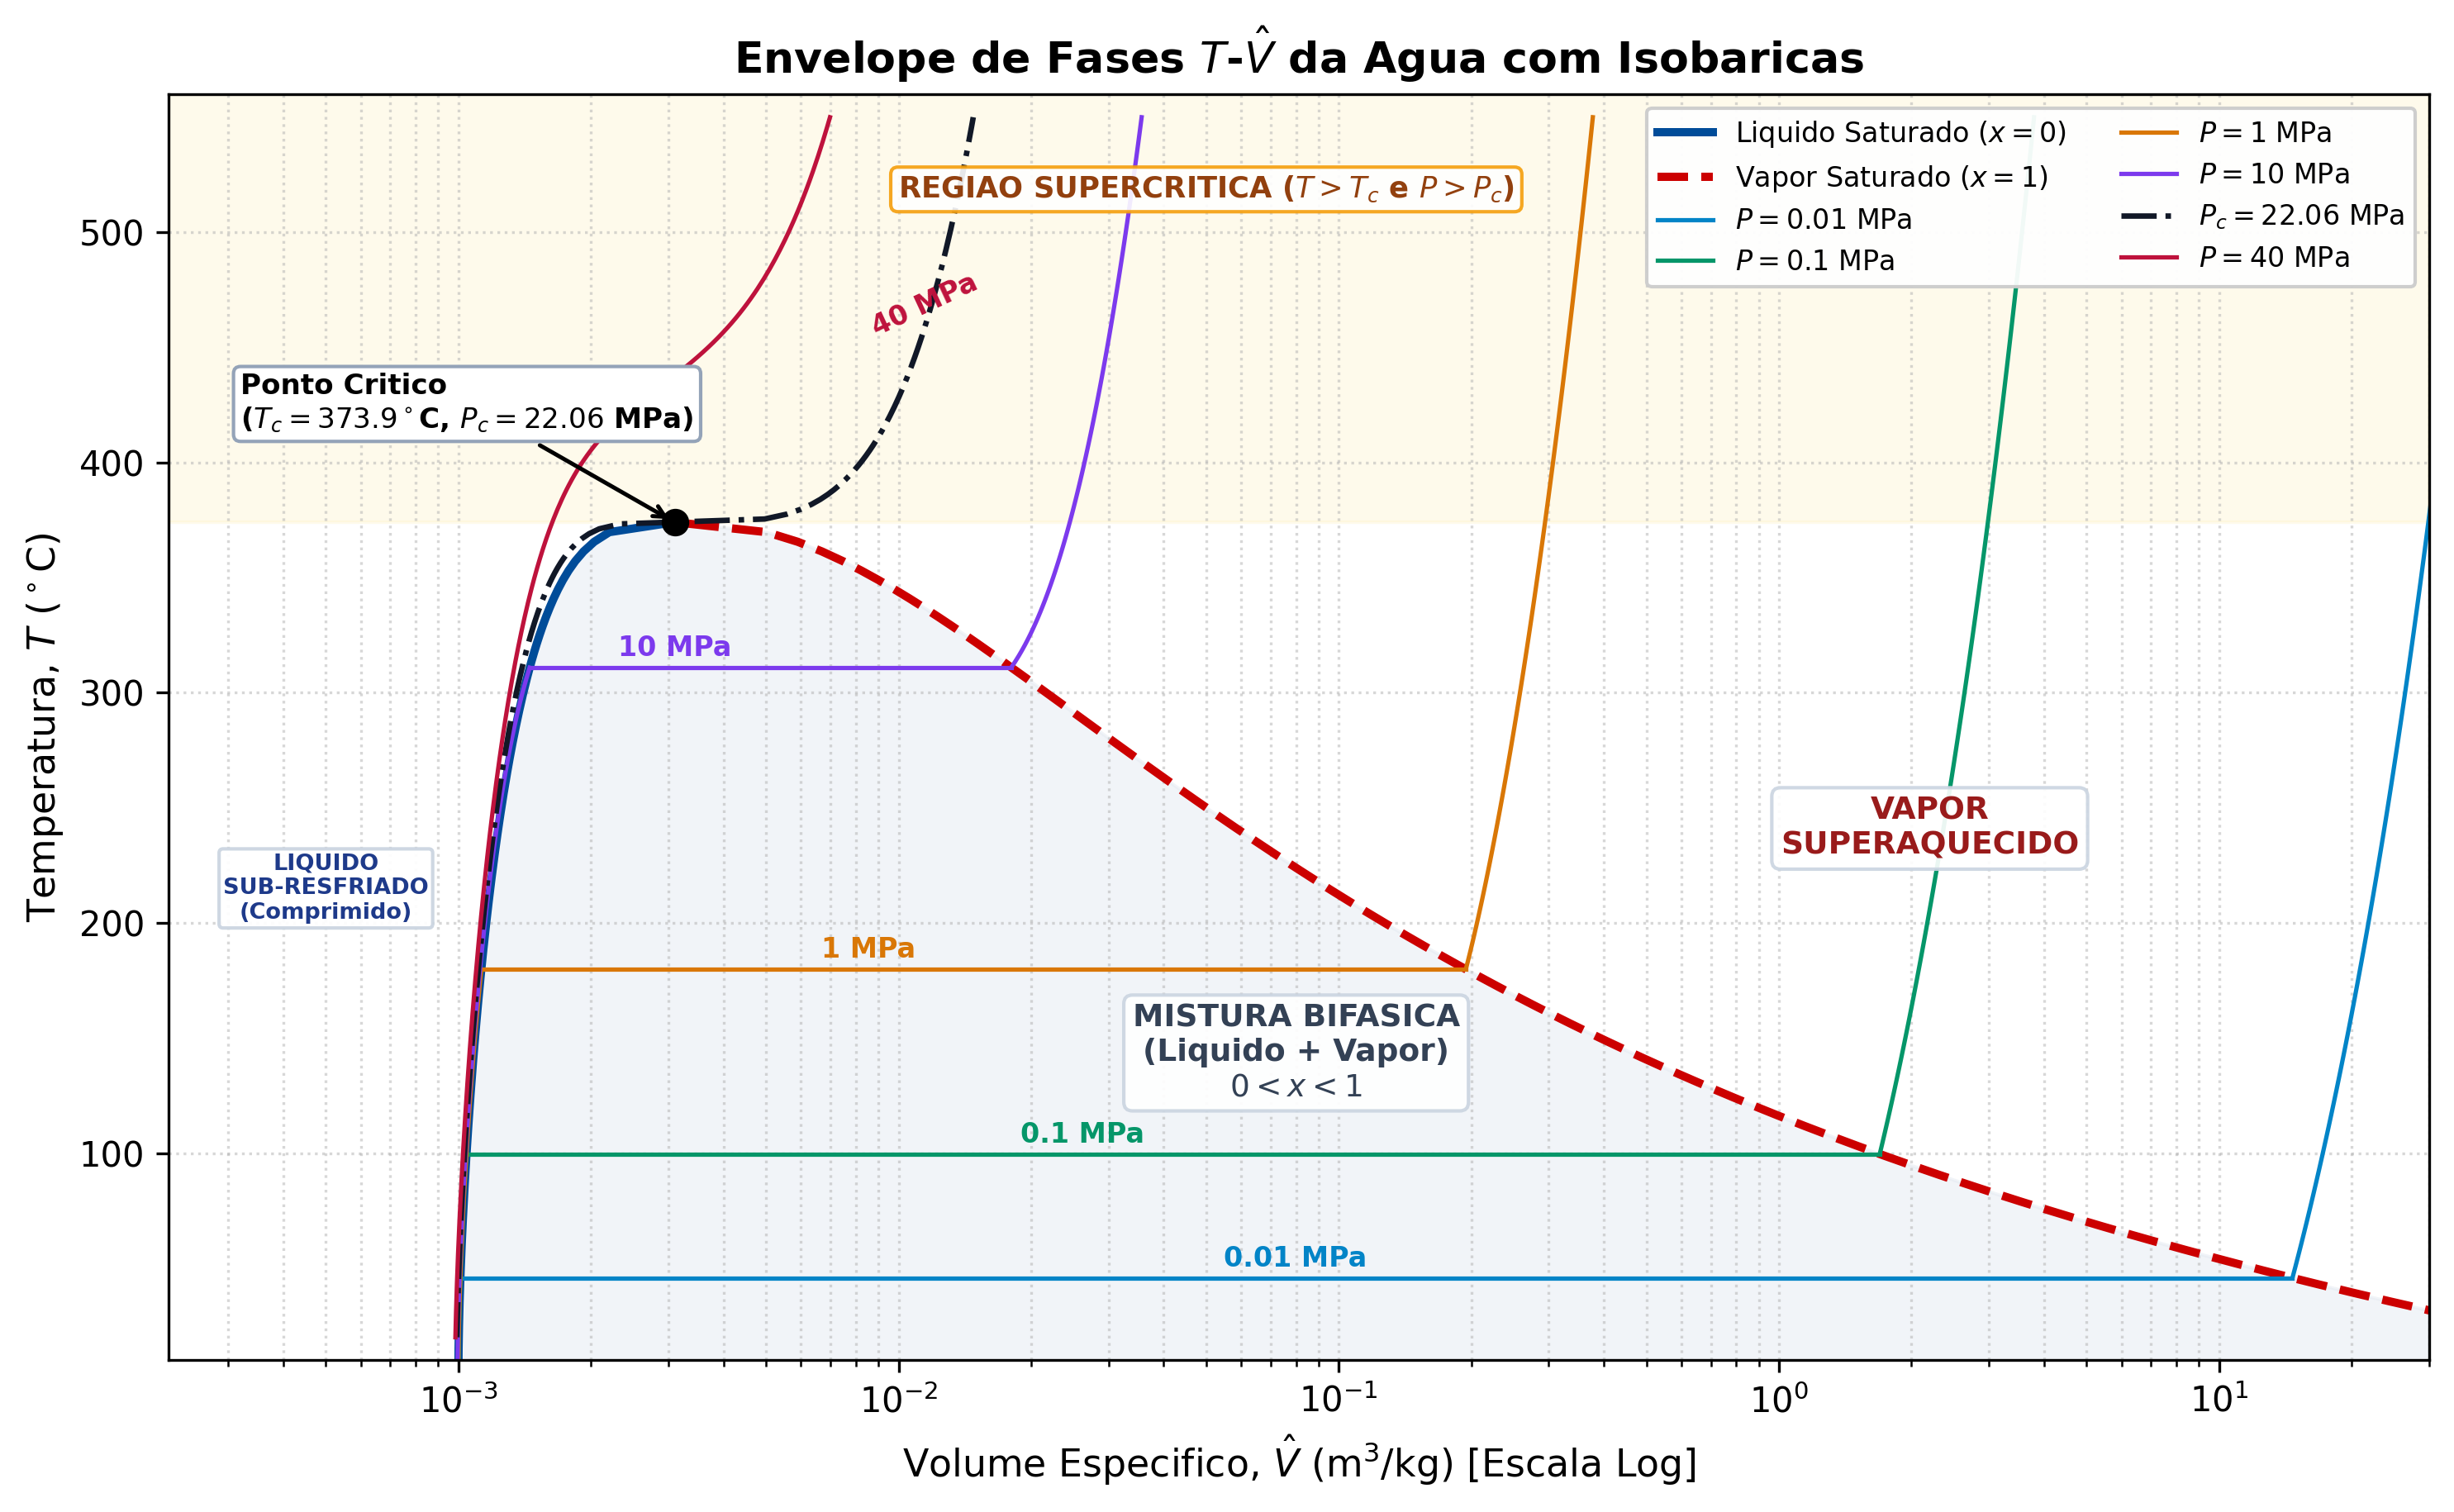

In [9]:
!pip install CoolProp --quiet

import numpy as np
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

fluido = 'Water'

# 1. Propriedades do Ponto Critico
P_crit = PropsSI('Pcrit', fluido)
T_crit = PropsSI('Tcrit', fluido) - 273.15
v_crit = 1.0 / PropsSI('rhocrit', fluido)

# 2. Vetor de 200 pressoes espacadas logaritmicamente (1 kPa ate P_crit)
pressoes = np.logspace(3, np.log10(P_crit - 200), 200)

# 3. Calculo das curvas de saturacao
T_sat = np.array([PropsSI('T', 'P', p, 'Q', 0, fluido) - 273.15 for p in pressoes])
v_f = np.array([1.0 / PropsSI('D', 'P', p, 'Q', 0, fluido) for p in pressoes])
v_g = np.array([1.0 / PropsSI('D', 'P', p, 'Q', 1, fluido) for p in pressoes])

fig, ax = plt.subplots(figsize=(10, 6.2), dpi=300)

# 4. Plotagem do Domo de Saturacao
ax.plot(v_f, T_sat, color='#004c99', linewidth=2.4, label='Liquido Saturado ($x=0$)')
ax.plot(v_g, T_sat, color='#cc0000', linestyle='--', linewidth=2.4, label='Vapor Saturado ($x=1$)')
ax.fill_betweenx(T_sat, v_f, v_g, color='#e2e8f0', alpha=0.45)

# 5. Linhas Isobaricas (Subcriticas, Critica e Supercritica)
isobaricas_MPa = [0.01, 0.1, 1.0, 10.0, P_crit / 1e6, 40.0]
cores_iso = ['#0284c7', '#059669', '#d97706', '#7c3aed', '#111827', '#be123c']

for P_mpa, cor in zip(isobaricas_MPa, cores_iso):
    P_pa = P_mpa * 1e6
    eh_critica = abs(P_pa - P_crit) < 1e4
    estilo = '-.' if eh_critica else '-'
    largura = 1.6 if eh_critica else 1.25
    rotulo_p = rf'$P_c = {P_mpa:.2f}$ MPa' if eh_critica else rf'$P = {P_mpa:g}$ MPa'

    if P_pa < P_crit:
        T_s = PropsSI('T', 'P', P_pa, 'Q', 0, fluido) - 273.15
        v_s_f = 1.0 / PropsSI('D', 'P', P_pa, 'Q', 0, fluido)
        v_s_g = 1.0 / PropsSI('D', 'P', P_pa, 'Q', 1, fluido)

        # Liquido comprimido (da base ate T_s)
        T_liq = np.linspace(10, T_s - 0.1, 60)
        v_liq = [1.0 / PropsSI('D', 'P', P_pa, 'T', t + 273.15, fluido) for t in T_liq]

        # Patamar bifasico
        v_pat = [v_s_f, v_s_g]
        T_pat = [T_s, T_s]

        # Vapor superaquecido (de T_s ate 550 C)
        T_vap = np.linspace(T_s + 0.1, 550, 100)
        v_vap = [1.0 / PropsSI('D', 'P', P_pa, 'T', t + 273.15, fluido) for t in T_vap]

        ax.plot(v_liq, T_liq, color=cor, linestyle=estilo, linewidth=largura)
        ax.plot(v_pat, T_pat, color=cor, linestyle=estilo, linewidth=largura, label=rotulo_p)
        ax.plot(v_vap, T_vap, color=cor, linestyle=estilo, linewidth=largura)

        # Rotulo direto no patamar
        v_mid = np.sqrt(v_s_f * v_s_g) * 0.45
        ax.text(v_mid, T_s + 5, f'{P_mpa:g} MPa', color=cor, fontsize=8, fontweight='bold')
    else:
        # Isobarica critica ou supercritica
        T_sup = np.linspace(20, 550, 250)
        v_sup = [1.0 / PropsSI('D', 'P', P_pa, 'T', t + 273.15, fluido) for t in T_sup]
        ax.plot(v_sup, T_sup, color=cor, linestyle=estilo, linewidth=largura, label=rotulo_p)
        if not eh_critica:
            ax.text(0.0085, 455, f'{P_mpa:g} MPa', color=cor, fontsize=8, fontweight='bold', rotation=25)

# Ponto Critico
ax.plot(v_crit, T_crit, 'ko', markersize=7, zorder=6)
ax.annotate(rf'Ponto Critico' + '\n' + rf'($T_c={T_crit:.1f}^\circ$C, $P_c={P_crit/1e6:.2f}$ MPa)',
            xy=(v_crit, T_crit), xytext=(0.00032, 415),
            fontsize=8.2, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#94a3b8'),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.2))

# 6. Identificacao das Regioes Termodinamicas
estilo_regiao = dict(boxstyle='round,pad=0.28', facecolor='white', edgecolor='#cbd5e1', alpha=0.92)
estilo_liq = dict(boxstyle='round,pad=0.18', facecolor='white', edgecolor='#cbd5e1', alpha=0.94)

ax.text(0.00050, 215, 'LIQUIDO\nSUB-RESFRIADO\n(Comprimido)', fontsize=6.5,
        fontweight='bold', color='#1e3a8a', ha='center', va='center', bbox=estilo_liq, zorder=5)

ax.text(0.08, 125, 'MISTURA BIFASICA\n(Liquido + Vapor)\n$0 < x < 1$', fontsize=9,
        fontweight='bold', color='#334155', ha='center', bbox=estilo_regiao)

ax.text(2.2, 230, 'VAPOR\nSUPERAQUECIDO', fontsize=9,
        fontweight='bold', color='#991b1b', ha='center', bbox=estilo_regiao)

ax.axhspan(T_crit, 560, color='#fef3c7', alpha=0.35, zorder=0)
ax.text(0.05, 515, 'REGIAO SUPERCRITICA ($T > T_c$ e $P > P_c$)', fontsize=8.5,
        fontweight='bold', color='#92400e', ha='center',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#f59e0b', alpha=0.9))

# Configuracoes finais dos eixos
ax.set_xscale('log')
ax.set_xlim(2.2e-4, 30)
ax.set_ylim(10, 560)
ax.set_xlabel(r'Volume Especifico, $\hat{V}$ ($\mathrm{m^3/kg}$) [Escala Log]', fontsize=11)
ax.set_ylabel(r'Temperatura, $T$ ($^\circ\mathrm{C}$)', fontsize=11)
ax.set_title(r'Envelope de Fases $T$-$\hat{V}$ da Agua com Isobaricas', fontsize=12.5, fontweight='bold')
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=8, ncol=2, frameon=True, facecolor='white', framealpha=0.95)

plt.tight_layout()
plt.savefig('envelope_agua_tv.png', dpi=300)
plt.show()